
# Hotel Booking Intelligence: Cancellation Prediction

## 1. Project Overview

Hotel booking cancellations can negatively affect hotel revenue, room availability, and operational planning. Predicting cancellations in advance can help hotels make better booking management decisions.

This project aims to develop a Machine Learning classification system that predicts whether a hotel booking is likely to be canceled based on its booking characteristics.

## 2. Problem Framing

**Problem:** Hotels face uncertainty when customers cancel their reservations, making it difficult to manage room availability and expected revenue.

**Proposed Solution:** Build a Machine Learning model that estimates the likelihood of booking cancellation using historical hotel booking data.

**Target Variable:** `is_canceled`
- `0`: Booking was not canceled.
- `1`: Booking was canceled.

**Business Decision:** Use cancellation predictions to identify potentially high-risk bookings and support actions such as early follow-up, booking confirmation, and risk-based reservation management.

## 3. Evaluation Metric

The project uses **F1-score** as the main metric for model tuning because it balances Precision and Recall.

Recall is also particularly important because missing a booking that will eventually be canceled may prevent the hotel from taking early action. Precision matters as well because incorrectly flagging bookings can lead to unnecessary interventions.

## 4. Project Workflow

1. Data Understanding
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Feature Engineering
5. Model Training and Comparison
6. Hyperparameter Tuning and Cross-Validation
7. Final Model Evaluation
8. Business Insights and Recommendations
9. Model Deployment using Streamlit


In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
file_path = "/content/drive/MyDrive/Hotel_Cancellation_Project/hotel_bookings.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
display(df.head())

In [ ]:
print("Original Rows:", len(df))
print("Original Columns:", len(df.columns))
print("Duplicate Rows:", df.duplicated().sum())


## 5. Data Understanding

### 5.1 Dataset Description

The project uses the Hotel Booking Demand dataset, which contains hotel booking records for City Hotels and Resort Hotels.

The dataset includes booking information such as hotel type, arrival dates, length of stay, number of guests, distribution channels, deposit types, customer characteristics, and cancellation status.

### 5.2 Dataset Dimensions

The dataset contains 119,390 rows and 32 columns before data cleaning.

Each row represents a hotel booking, and each column describes a booking attribute or its outcome.

### 5.3 Target Variable

The target variable is `is_canceled`:

- `0`: Booking was not canceled.
- `1`: Booking was canceled.


In [68]:

# Dataset Information

print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  


In [69]:

# Missing Values Analysis

missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[missing_values["Missing Values"] > 0]
missing_values = missing_values.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_values)


,Missing Values,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


In [70]:

# Target Class Distribution

class_distribution = df["is_canceled"].value_counts().sort_index()

class_percentage = (
    df["is_canceled"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Bookings": class_distribution,
    "Percentage": class_percentage
})

target_summary.index = ["Not Canceled (0)", "Canceled (1)"]

display(target_summary)


,Bookings,Percentage
Not Canceled (0),75166,62.958372
Canceled (1),44224,37.041628



### 5.4 Data Understanding Observations

- The dataset contains 119,390 booking records and 32 features.
- The `company` column has approximately 94.31% missing values, making it unsuitable for direct use without a special treatment.
- The `agent` column has 13.69% missing values, while `country` has only 0.41%.
- The `children` column contains only 4 missing values.
- Approximately 62.96% of bookings were not canceled, while 37.04% were canceled.
- The target variable shows a moderate class imbalance, which makes evaluating Precision, Recall, and F1-score important during model development.


###EDA

In [ ]:
# Target distribution
plt.figure()
sns.countplot(data=df, x="is_canceled")
plt.title("Booking Cancellation Distribution")
plt.xlabel("Cancellation Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Bookings")
plt.show()


**Observation:**

The majority of bookings were not canceled, representing approximately 62.96% of the dataset, while canceled bookings accounted for 37.04%.

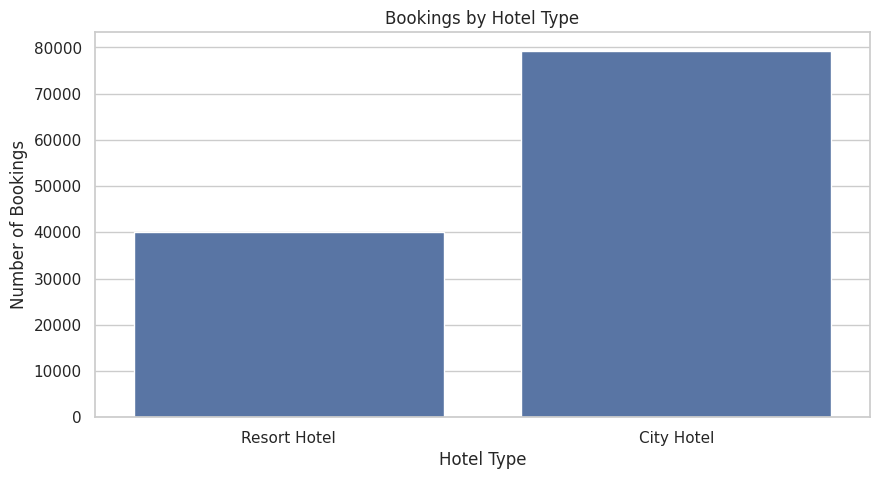

In [71]:
# Hotel distribution
plt.figure()
sns.countplot(data=df, x="hotel")
plt.title("Bookings by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.show()


**Observation:**

City Hotels account for approximately 66.4% of all bookings, while Resort Hotels represent around 33.6%.

This indicates that City Hotels contribute a larger share of the booking records in the dataset.


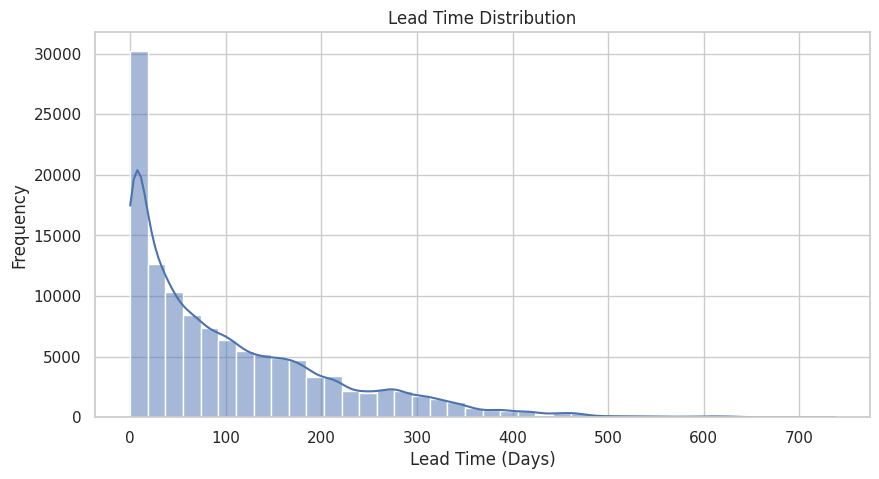

In [73]:
# Lead time distribution
plt.figure()
sns.histplot(data=df, x="lead_time", bins=40, kde=True)
plt.title("Lead Time Distribution")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Frequency")
plt.show()

**Observation:**

The Lead Time distribution is positively skewed. Most bookings are made within a relatively short period before arrival, while fewer bookings have a very long lead time.

In [ ]:
# Market segment distribution
plt.figure()
sns.countplot(
    data=df,
    y="market_segment",
    order=df["market_segment"].value_counts().index
)
plt.title("Bookings by Market Segment")
plt.xlabel("Number of Bookings")
plt.ylabel("Market Segment")
plt.show()

**Observation:**

Online Travel Agents (Online TA) represent the largest booking segment, followed by Offline Travel Agents/Tour Operators (Offline TA/TO). Other segments contribute smaller proportions of total bookings.

In [ ]:
# Deposit type distribution
plt.figure()
sns.countplot(data=df, x="deposit_type")
plt.title("Bookings by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Number of Bookings")
plt.show()

**Observation:**

Most bookings were made without a deposit (No Deposit). Non-refundable bookings represent a smaller proportion, while refundable bookings account for a very small number of reservations.

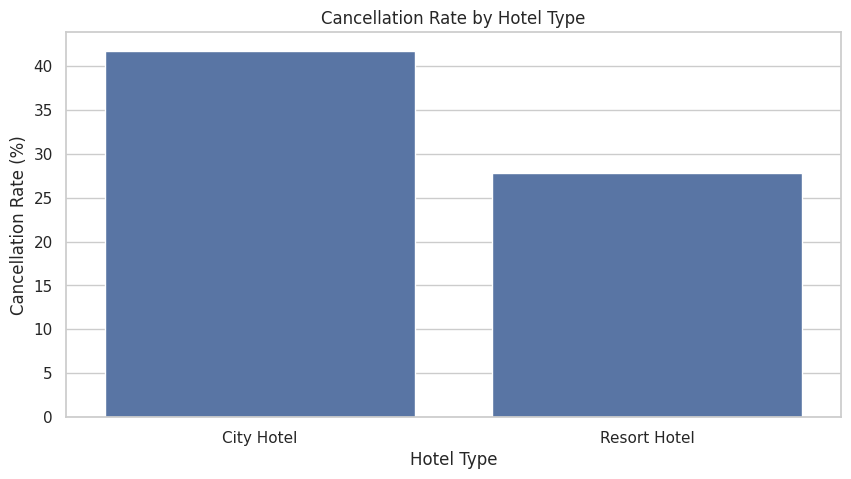

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64


In [72]:
# Cancellation Rate by Hotel Type

hotel_cancel = df.groupby("hotel")["is_canceled"].mean() * 100

plt.figure()
sns.barplot(
    x=hotel_cancel.index,
    y=hotel_cancel.values
)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

print(hotel_cancel)

**Observation:**

City Hotels have a higher cancellation rate (41.73%)
compared to Resort Hotels (27.76%).

This indicates that booking cancellations are more
common in City Hotels than in Resort Hotels.

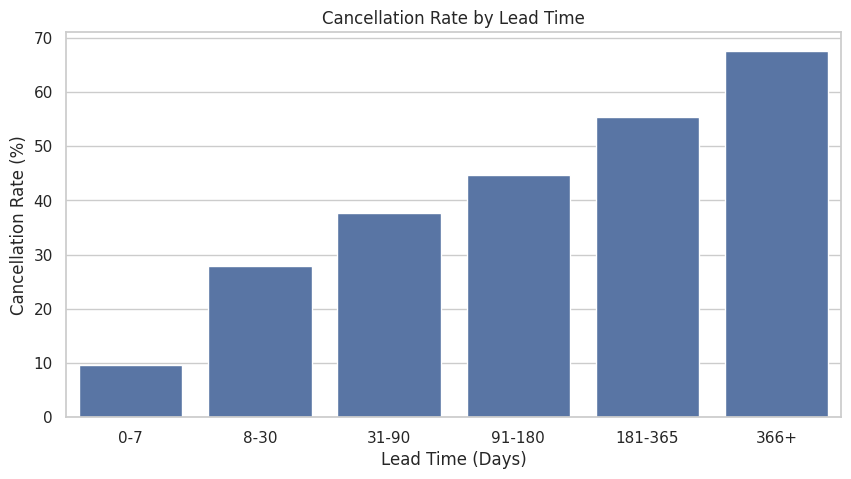

lead_time_group
0-7         9.632331
8-30       27.863924
31-90      37.698372
91-180     44.710466
181-365    55.453955
366+       67.662008
Name: is_canceled, dtype: float64


In [74]:
# Lead Time Groups
df_eda = df.copy()

df_eda["lead_time_group"] = pd.cut(
    df_eda["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
)

# Cancellation Rate by Lead Time
lead_cancel = (
    df_eda.groupby("lead_time_group", observed=False)["is_canceled"]
    .mean() * 100
)

plt.figure()
sns.barplot(
    x=lead_cancel.index,
    y=lead_cancel.values
)

plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Cancellation Rate (%)")
plt.show()

print(lead_cancel)

**Observation:**

The cancellation rate increases as the lead time increases.

Bookings made more than 366 days before arrival have
the highest cancellation rate (67.66%), while bookings
made within 7 days of arrival have the lowest rate
(9.63%).

This suggests a positive relationship between lead
time and booking cancellation.

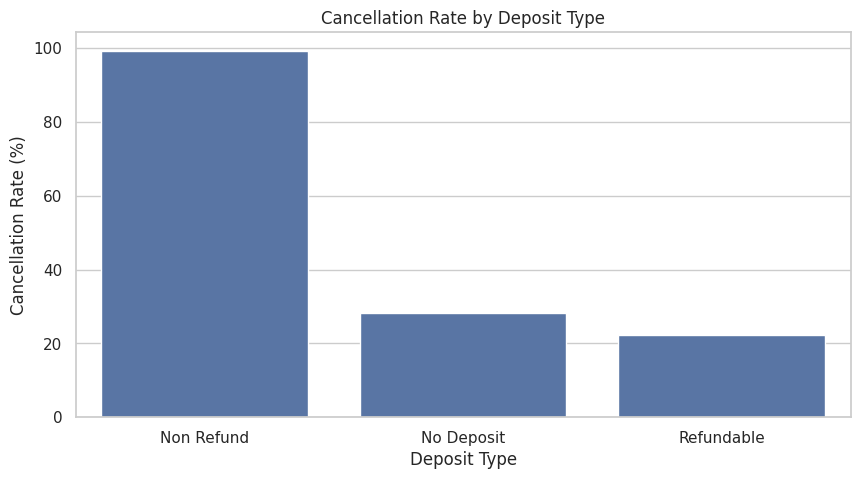

deposit_type
Non Refund    99.362446
No Deposit    28.377022
Refundable    22.222222
Name: is_canceled, dtype: float64


In [75]:
# Cancellation Rate by Deposit Type

deposit_cancel = (
    df.groupby("deposit_type")["is_canceled"]
    .mean() * 100
).sort_values(ascending=False)

plt.figure()

sns.barplot(
    x=deposit_cancel.index,
    y=deposit_cancel.values
)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.show()

print(deposit_cancel)

**Observation:**

Non-refundable bookings show an exceptionally high
cancellation rate of 99.36%, with 14,494 cancellations
out of 14,587 bookings.

Bookings without a deposit have a cancellation rate
of 28.38%, while refundable bookings have a rate of
22.22%.

The refundable category contains only 162 bookings,
so its result should be interpreted cautiously.

The unusually high cancellation rate of non-refundable
bookings requires further investigation.

In [ ]:
deposit_analysis = df.groupby("deposit_type")["is_canceled"].agg(
    Total_Bookings="count",
    Canceled_Bookings="sum",
    Cancellation_Rate="mean"
)

deposit_analysis["Cancellation_Rate"] *= 100

display(deposit_analysis)

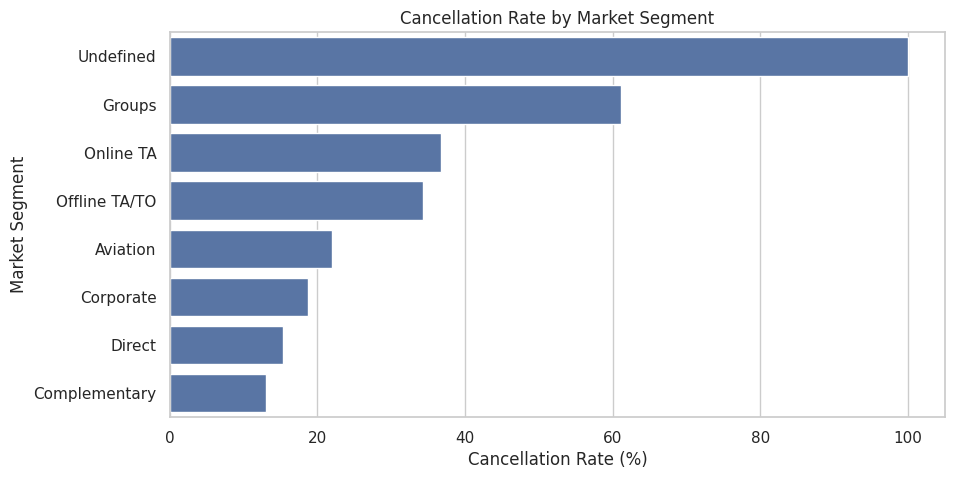

market_segment
Undefined        100.000000
Groups            61.062036
Online TA         36.721143
Offline TA/TO     34.316033
Aviation          21.940928
Corporate         18.734655
Direct            15.341901
Complementary     13.055182
Name: is_canceled, dtype: float64


In [76]:
# Cancellation Rate by Market Segment

segment_cancel = (
    df.groupby("market_segment")["is_canceled"]
    .mean() * 100
).sort_values(ascending=False)

plt.figure()

sns.barplot(
    x=segment_cancel.values,
    y=segment_cancel.index
)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Market Segment")
plt.show()

print(segment_cancel)

In [ ]:
segment_analysis = df.groupby("market_segment")["is_canceled"].agg(
    Total_Bookings="count",
    Canceled_Bookings="sum",
    Cancellation_Rate="mean"
)

segment_analysis["Cancellation_Rate"] *= 100

display(segment_analysis.sort_values(
    "Cancellation_Rate",
    ascending=False
))


**Observation:**

The Groups segment has the highest cancellation rate among the defined market segments (61.06%), followed by Online TA (36.72%) and Offline TA/TO (34.32%).

Direct bookings have a relatively low cancellation rate of 15.34%, while Complementary bookings show a rate of 13.06%.

The Undefined category has a 100% cancellation rate, but this result should be interpreted cautiously because it represents bookings with an unspecified market segment.

These findings suggest that cancellation behavior varies considerably across market segments.


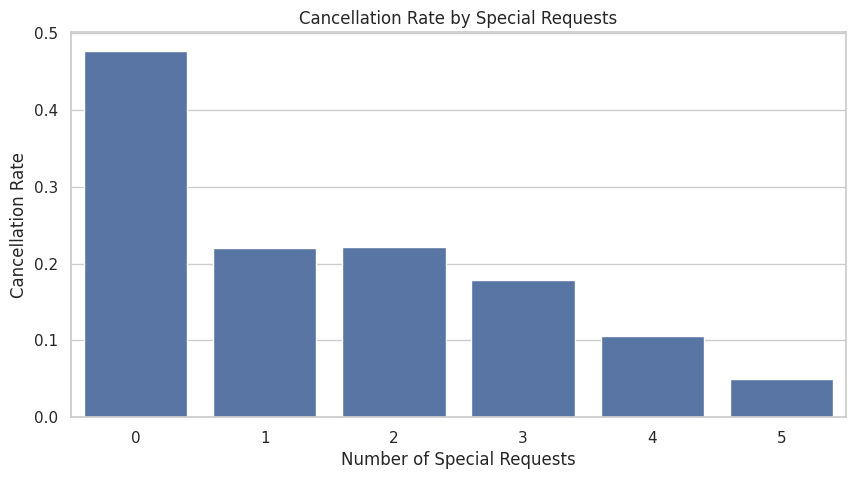

,count,mean
total_of_special_requests,,
0,70318,47.720356
1,33226,22.024920
2,12969,22.098851
3,2497,17.861434
4,340,10.588235
5,40,5.000000


In [77]:
# Cancellation Rate by Special Requests

plt.figure()

sns.barplot(
    data=df,
    x="total_of_special_requests",
    y="is_canceled",
    errorbar=None
)

plt.title("Cancellation Rate by Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate")

plt.show()

# Display cancellation rates
special_requests_analysis = (
    df.groupby("total_of_special_requests")["is_canceled"]
    .agg(["count", "mean"])
)

special_requests_analysis["mean"] *= 100

display(special_requests_analysis)

**Observation:**

Bookings with no special requests have the highest
cancellation rate (47.72%).

In general, the cancellation rate tends to decrease
as the number of special requests increases.

Bookings with five special requests have a cancellation
rate of only 5%, although this group contains just
40 bookings and should be interpreted cautiously.

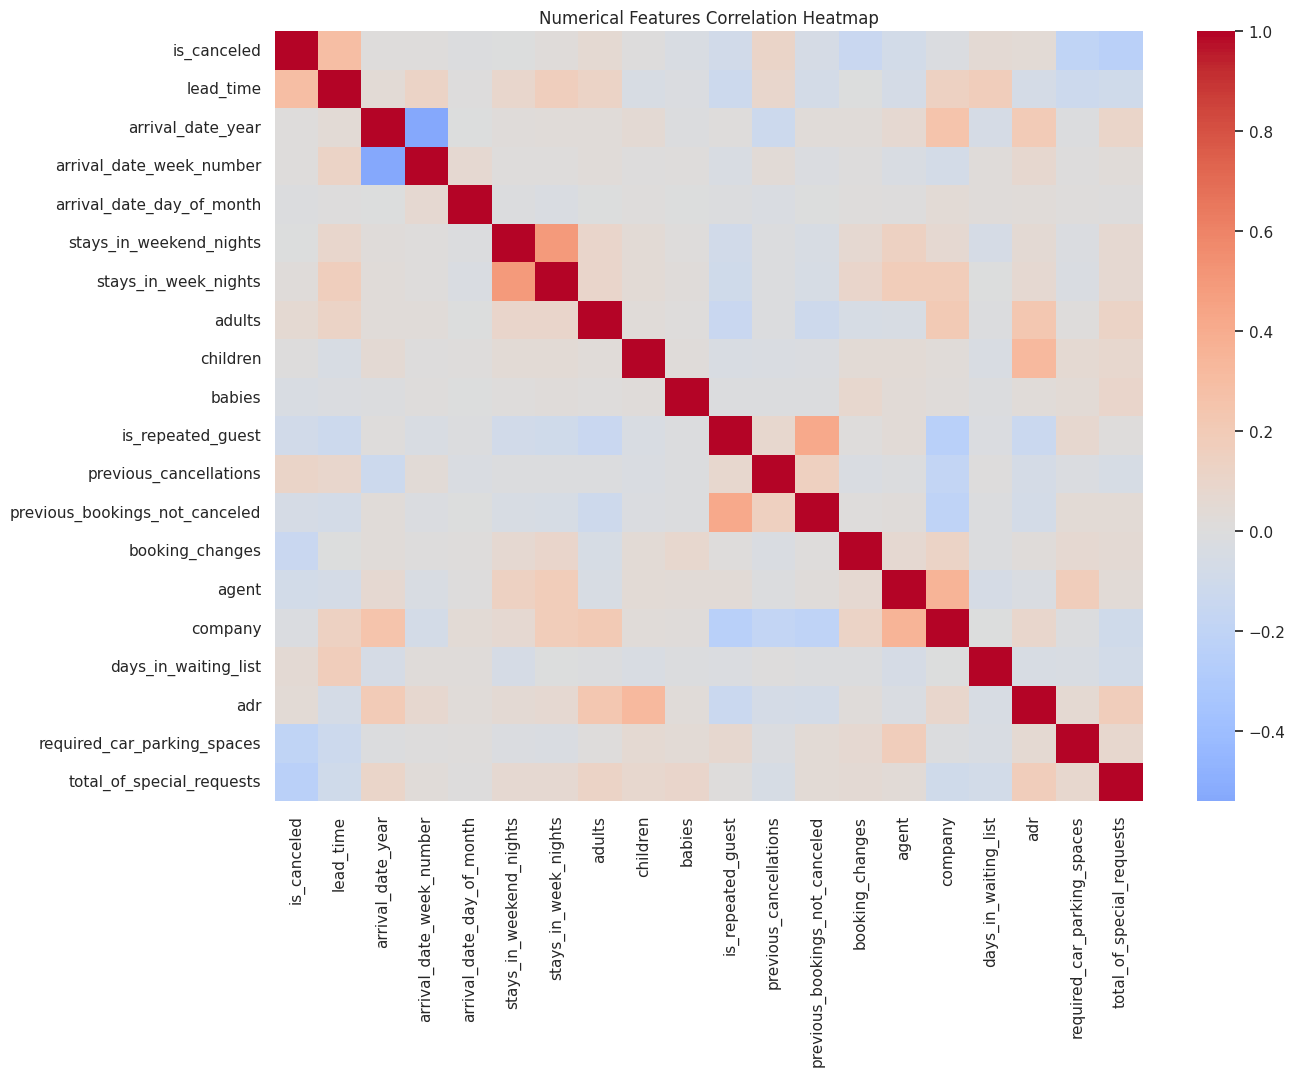

In [78]:
# Numerical Features Correlation Heatmap

numeric_df = df.select_dtypes(include=["number"])

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Numerical Features Correlation Heatmap")
plt.show()


**Observation:**

The correlation heatmap shows generally weak to moderate linear relationships among most numerical features.

Some positive correlations can be observed between:
- Weekend nights and weekday nights.
- Previous cancellations and previous bookings not canceled.

The target variable `is_canceled` does not show a very strong linear correlation with most individual numerical features.

This suggests that booking cancellation may depend on multiple factors rather than a single numerical variable.

Correlation does not imply causation, and weak linear correlation does not necessarily mean that a feature is unimportant for prediction.


In [ ]:
# Correlation with Target Variable

target_corr = numeric_df.corr()["is_canceled"].drop("is_canceled")

target_corr = target_corr.sort_values(
    ascending=False,
    key=abs
)

display(target_corr)

**Observation:**

Lead time has the strongest positive correlation
with booking cancellation (0.293).

Total special requests show the strongest negative
correlation with cancellation (-0.235).

Other features, such as required car parking spaces
and booking changes, also show negative correlations.

Overall, the numerical features have mostly weak
to moderate linear correlations with the target.

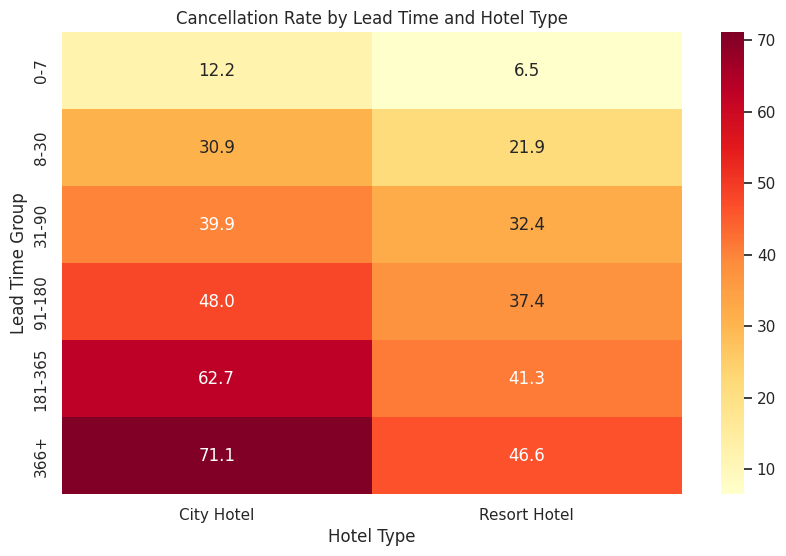

In [79]:
# Cancellation Rate by Lead Time and Hotel Type

lead_hotel = pd.pivot_table(
    df_eda,
    index="lead_time_group",
    columns="hotel",
    values="is_canceled",
    aggfunc="mean",
    observed=False
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    lead_hotel,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Cancellation Rate by Lead Time and Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Lead Time Group")

plt.show()

**Observation:**

The cancellation rate increases with lead time in both
City Hotels and Resort Hotels.

City Hotels consistently show higher cancellation
rates than Resort Hotels across all lead time groups.

The highest cancellation rate (71.1%) is observed
in City Hotel bookings with a lead time greater than
366 days, while the lowest rate (6.5%) occurs in
Resort Hotel bookings made within 7 days of arrival.

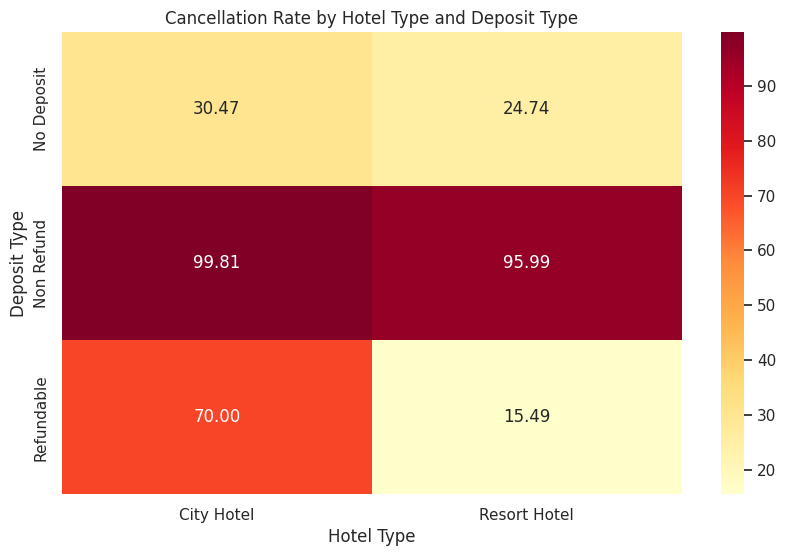

In [80]:
# Cancellation Rate by Hotel Type and Deposit Type

deposit_hotel = pd.pivot_table(
    df,
    index="deposit_type",
    columns="hotel",
    values="is_canceled",
    aggfunc="mean"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    deposit_hotel,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Cancellation Rate by Hotel Type and Deposit Type")
plt.xlabel("Hotel Type")
plt.ylabel("Deposit Type")

plt.show()


**Observation:**

Non-refundable bookings show exceptionally high cancellation rates in both hotel types, reaching 99.81% for City Hotels and 95.99% for Resort Hotels.

Bookings without a deposit show comparatively lower cancellation rates (30.47% for City Hotels and 24.74% for Resort Hotels).

Refundable bookings show a considerable difference between City Hotels (70%) and Resort Hotels (15.49%). However, these results should be interpreted cautiously because the refundable category contains relatively few bookings.

Overall, cancellation patterns vary depending on both hotel type and deposit type.


In [81]:
# Booking Counts by Hotel and Deposit Type

deposit_hotel_counts = pd.crosstab(
    df["deposit_type"],
    df["hotel"]
)

display(deposit_hotel_counts)

hotel,City Hotel,Resort Hotel
deposit_type,,
No Deposit,66442,38199
Non Refund,12868,1719
Refundable,20,142


**Observation:**

Non-refundable bookings show exceptionally high
cancellation rates in both hotel types.

Bookings without a deposit represent the largest
category in both City Hotels and Resort Hotels.

Refundable bookings show different cancellation
rates across hotel types. However, this category
has relatively few observations, especially in
City Hotels, so the results should be interpreted
cautiously.

### DATA CLEANING

In [82]:
# Check Duplicate Records

print("Dataset Shape Before Removing Duplicates:", df.shape)

duplicates = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicates)

# Remove Exact Duplicate Rows
df = df.drop_duplicates()

# Reset Index
df = df.reset_index(drop=True)

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape Before Removing Duplicates: (119390, 32)
Number of Duplicate Rows: 31994
Dataset Shape After Removing Duplicates: (87396, 32)
Remaining Duplicates: 0


**Observation:**

The original dataset contained 31,994 exact duplicate
rows. These duplicate records were removed to reduce
redundancy in the dataset.

After removing duplicates, the dataset contains
87,396 records with no remaining exact duplicate rows.

In [83]:
# Check Missing Values

missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": df.isnull().mean() * 100
})

missing_values = missing_values[
    missing_values["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_values)

,Missing Values,Percentage
company,82137,93.982562
agent,12193,13.951439
country,452,0.517186
children,4,0.004577


In [84]:
# 1. Drop company column
df = df.drop(columns=["company"])

# 2. Fill missing agent values
df["agent"] = df["agent"].fillna("Unknown")

# 3. Fill missing country values
df["country"] = df["country"].fillna("Unknown")

# 4. Fill missing children values with median
children_median = df["children"].median()
df["children"] = df["children"].fillna(children_median)

# Check missing values after treatment
print("Missing Values After Treatment:")
print(df.isnull().sum().sum())

# Display remaining missing values
display(df.isnull().sum()[df.isnull().sum() > 0])

Missing Values After Treatment:
0


,0


**Observation:**

The company column was removed due to its extremely
high percentage of missing values (93.98%).

Missing values in the agent and country columns
were replaced with "Unknown" to preserve the records.

Missing values in the children column were replaced
using the median value.

These treatments were applied to reduce missing data
while preserving as much useful information as possible.

In [ ]:
# Select Numerical Features for Outlier Detection

outlier_columns = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

# Plot Boxplots
plt.figure(figsize=(16, 10))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [85]:
# Detect Outliers using IQR

outlier_summary = []

for col in outlier_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Outliers": len(outliers),
        "Percentage": len(outliers) / len(df) * 100,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Feature,Outliers,Percentage,Lower Bound,Upper Bound
0,lead_time,2396,2.741544,-160.0,296.0
1,stays_in_weekend_nights,220,0.251728,-3.0,5.0
2,stays_in_week_nights,1531,1.751796,-3.5,8.5
3,adults,22899,26.201428,2.0,2.0
4,children,8364,9.570232,0.0,0.0
5,babies,914,1.045814,0.0,0.0
6,previous_cancellations,1685,1.928006,0.0,0.0
7,previous_bookings_not_canceled,3545,4.056250,0.0,0.0
8,booking_changes,15902,18.195341,0.0,0.0
9,days_in_waiting_list,860,0.984027,0.0,0.0


In [ ]:
# Inspect Numerical Features

columns_to_inspect = [
    "adults",
    "children",
    "babies",
    "adr",
    "lead_time",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

# Statistical Summary
display(df[columns_to_inspect].describe().T)

# Check Unusual Values
print("Negative ADR Values:")
print((df["adr"] < 0).sum())

print("\nZero Adult Bookings:")
print((df["adults"] == 0).sum())

print("\nBookings with No Guests:")
print(
    ((df["adults"] + df["children"] + df["babies"]) == 0).sum()
)

print("\nHighest ADR Values:")
display(df["adr"].nlargest(10))

print("\nHighest Adult Counts:")
display(df["adults"].value_counts().sort_index())

In [ ]:
# Investigate Suspicious Records

# 1. Negative ADR
negative_adr = df[df["adr"] < 0]

print("Negative ADR Records:")
display(negative_adr)

# 2. Bookings Without Any Guests
no_guests = df[
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
]

print("Bookings Without Guests:", len(no_guests))
display(no_guests.head(10))

# 3. Extremely High ADR
high_adr = df[df["adr"] > 1000]

print("ADR Above 1000:")
display(high_adr)

# 4. Unusually High Adult Counts
high_adults = df[df["adults"] > 10]

print("Bookings With More Than 10 Adults:")
display(high_adults)

In [ ]:
# Inspect Extreme ADR
print("ADR = 5400:")
display(df[df["adr"] > 1000])

# Inspect Bookings Without Guests
print("Bookings Without Guests:")
display(
    df[
        (df["adults"] == 0) &
        (df["children"] == 0) &
        (df["babies"] == 0)
    ].head(10)
)

# Inspect Large Group Bookings
print("Bookings with More Than 10 Adults:")

display(
    df[df["adults"] > 10][[
        "hotel",
        "adults",
        "children",
        "babies",
        "customer_type",
        "is_canceled",
        "adr"
    ]]
)

In [86]:
# Outlier Treatment

print("Dataset Shape Before Treatment:", df.shape)

# 1. Identify invalid records
negative_adr_mask = df["adr"] < 0

no_guests_mask = (
    (df["adults"] == 0) &
    (df["children"] == 0) &
    (df["babies"] == 0)
)

extreme_adr_mask = df["adr"] > 1000

# 2. Count records before removal
print("Negative ADR Records:", negative_adr_mask.sum())
print("Bookings Without Guests:", no_guests_mask.sum())
print("Extreme ADR Records:", extreme_adr_mask.sum())

# 3. Combine invalid records
invalid_records = (
    negative_adr_mask |
    no_guests_mask |
    extreme_adr_mask
)

# 4. Remove invalid records
df = df.loc[~invalid_records].copy()

# 5. Reset index
df.reset_index(drop=True, inplace=True)

# 6. Final verification
print("\nDataset Shape After Treatment:", df.shape)
print("Remaining Negative ADR:", (df["adr"] < 0).sum())
print("Remaining Extreme ADR:", (df["adr"] > 1000).sum())

print(
    "Remaining Bookings Without Guests:",
    (
        (df["adults"] == 0) &
        (df["children"] == 0) &
        (df["babies"] == 0)
    ).sum()
)

Dataset Shape Before Treatment: (87396, 31)
Negative ADR Records: 1
Bookings Without Guests: 166
Extreme ADR Records: 1

Dataset Shape After Treatment: (87228, 31)
Remaining Negative ADR: 0
Remaining Extreme ADR: 0
Remaining Bookings Without Guests: 0



**Observation:**

The dataset initially contained 1 booking with a negative ADR, 166 bookings without any guests, and 1 booking with an extremely high ADR above 1000.

These 168 invalid records were removed to improve data quality.

After treatment, the dataset contained 87,228 records, with no remaining negative ADR values, extreme ADR values above 1000, or bookings without guests.

The IQR method was used for outlier detection, while removal was limited to records identified as invalid based on the selected business rules.


# Feature Engineering

In [87]:
# Identify Categorical and Numerical Features

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

print("\nCategorical Features Summary:")
display(df[categorical_columns].nunique().sort_values())

Categorical Columns:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type', 'reservation_status', 'reservation_status_date']

Numerical Columns:
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Features Summary:


,0
hotel,2
deposit_type,3
reservation_status,3
customer_type,4
distribution_channel,5
meal,5
market_segment,8
reserved_room_type,9
assigned_room_type,11
arrival_date_month,12


In [88]:
# Separate Features and Target

X = df.drop(columns=[
    "is_canceled",
    "reservation_status",
    "reservation_status_date"
])

y = df["is_canceled"]

# Identify Categorical and Numerical Features

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:", len(categorical_features))
print(categorical_features)

print("\nNumerical Features:", len(numerical_features))
print(numerical_features)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Categorical Features: 11
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type']

Numerical Features: 17
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Features Shape: (87228, 28)
Target Shape: (87228,)


In [89]:

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset shapes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Check target distribution

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (69782, 28)
Testing Features: (17446, 28)
Training Target: (69782,)
Testing Target: (17446,)

Training Target Distribution:
is_canceled
0    72.477143
1    27.522857
Name: proportion, dtype: float64

Testing Target Distribution:
is_canceled
0    72.475066
1    27.524934
Name: proportion, dtype: float64


In [90]:
# Convert Categorical Features to String

for col in categorical_features:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

print("Categorical Features Converted Successfully!")

print(X_train[categorical_features].dtypes)

Categorical Features Converted Successfully!
hotel                   object
arrival_date_month      object
meal                    object
country                 object
market_segment          object
distribution_channel    object
reserved_room_type      object
assigned_room_type      object
deposit_type            object
agent                   object
customer_type           object
dtype: object


In [92]:


# Numerical Preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical Preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("to_string", FunctionTransformer(
        lambda x: x.astype(str),
        feature_names_out="one-to-one"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10
        ))
    ]
)

# Combine Transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Create Pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

# Fit on Training Data
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

# Transform Testing Data
X_test_processed = preprocessing_pipeline.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (69782, 332)
Testing Data Shape: (17446, 332)


**Observation:**

Numerical features were standardized using StandardScaler,
while categorical features were encoded using OneHotEncoder.

A ColumnTransformer was used to apply the appropriate
transformation to each feature type.

The preprocessing pipeline was fitted on the training
data and applied to the testing data to prevent data leakage.

After preprocessing, both datasets contain 332 features.

In [ ]:
import numpy as np
from scipy.sparse import issparse

# Check NaN and Infinite Values

print("Training NaN:",
      np.isnan(X_train_processed.data if issparse(X_train_processed)
               else X_train_processed).sum())

print("Testing NaN:",
      np.isnan(X_test_processed.data if issparse(X_test_processed)
               else X_test_processed).sum())

print("Training Infinite Values:",
      np.isinf(X_train_processed.data if issparse(X_train_processed)
               else X_train_processed).sum())

print("Testing Infinite Values:",
      np.isinf(X_test_processed.data if issparse(X_test_processed)
               else X_test_processed).sum())

# Check Target Distribution
print("\nFinal Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

**Observation:**

The preprocessing validation confirmed that both
training and testing datasets contain no missing
or infinite values.

The target distribution was preserved after the
stratified train-test split.

The dataset is now ready for machine learning modeling.

In [95]:


# Create Baseline Model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train Model
baseline_model.fit(X_train_processed, y_train)

# Make Predictions
baseline_predictions = baseline_model.predict(
    X_test_processed
)

# Evaluate Model
print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    baseline_predictions
))

Baseline Accuracy: 0.7247506591768886

Classification Report:
              precision    recall  f1-score   support

           0       0.72      1.00      0.84     12644
           1       0.00      0.00      0.00      4802

    accuracy                           0.72     17446
   macro avg       0.36      0.50      0.42     17446
weighted avg       0.53      0.72      0.61     17446


Confusion Matrix:
[[12644     0]
 [ 4802     0]]


**Observation:**

The Baseline Model achieved an accuracy of 72.48%.

However, it failed to identify any canceled bookings,
resulting in zero precision, recall, and F1-score
for class 1.

This demonstrates that accuracy alone is not a
sufficient evaluation metric for this classification
problem.

More advanced models are needed to identify
canceled bookings effectively.

###LOGISTIC REGRESSION

In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create Logistic Regression Model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train Model
lr_model.fit(X_train_processed, y_train)

# Make Predictions
lr_predictions = lr_model.predict(X_test_processed)

# Evaluate Model
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    lr_predictions
))

print("\nROC-AUC Score:",
      roc_auc_score(
          y_test,
          lr_model.predict_proba(X_test_processed)[:, 1]
      ))

Logistic Regression Accuracy: 0.8071191103977989

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87     12644
           1       0.69      0.54      0.61      4802

    accuracy                           0.81     17446
   macro avg       0.77      0.72      0.74     17446
weighted avg       0.80      0.81      0.80     17446


Confusion Matrix:
[[11488  1156]
 [ 2209  2593]]

ROC-AUC Score: 0.8692956763243617


**Observation:**

Logistic Regression achieved an accuracy of 80.71%
and a ROC-AUC score of 0.8693.

The model achieved 69% precision and 54% recall
for canceled bookings, with an F1-score of 0.61.

Compared to the baseline model, Logistic Regression
significantly improved cancellation detection.

However, the model still misses some canceled
bookings, indicating room for further improvement.

###DESCISION TREE CLASSIFIER

In [97]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create Decision Tree Model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train Model
dt_model.fit(X_train_processed, y_train)

# Make Predictions
dt_predictions = dt_model.predict(X_test_processed)

# Evaluate Model
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_predictions
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    dt_predictions
))

print("\nROC-AUC Score:",
      roc_auc_score(
          y_test,
          dt_model.predict_proba(X_test_processed)[:, 1]
      ))

Decision Tree Accuracy: 0.8019030150177691

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86     12644
           1       0.64      0.65      0.64      4802

    accuracy                           0.80     17446
   macro avg       0.75      0.76      0.75     17446
weighted avg       0.80      0.80      0.80     17446


Confusion Matrix:
[[10858  1786]
 [ 1670  3132]]

ROC-AUC Score: 0.7574515508868035


**Observation:**

The Decision Tree model achieved an accuracy of 80.19%
and a ROC-AUC score of 0.7575.

It achieved 64% precision and 65% recall for canceled
bookings, with an F1-score of 0.64.

Compared to Logistic Regression, Decision Tree
achieved higher recall and F1-score for class 1,
but lower accuracy and ROC-AUC.

This indicates a trade-off between detecting more
canceled bookings and overall model discrimination.

###RANDOM FOREST MODEL

In [98]:

# Create Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train Model
rf_model.fit(X_train_processed, y_train)

# Make Predictions
rf_predictions = rf_model.predict(X_test_processed)

# Evaluate Model
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    rf_predictions
))

print("\nROC-AUC Score:",
      roc_auc_score(
          y_test,
          rf_model.predict_proba(X_test_processed)[:, 1]
      ))

Random Forest Accuracy: 0.8534334517941076

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     12644
           1       0.78      0.66      0.71      4802

    accuracy                           0.85     17446
   macro avg       0.83      0.79      0.81     17446
weighted avg       0.85      0.85      0.85     17446


Confusion Matrix:
[[11737   907]
 [ 1650  3152]]

ROC-AUC Score: 0.9130463870044657


**Observation:**

The Random Forest model achieved an accuracy of 85.34%
and a ROC-AUC score of 0.9130.

It achieved 78% precision and 66% recall for canceled
bookings, with an F1-score of 0.71.

Compared to Logistic Regression and Decision Tree,
Random Forest achieved better overall performance
across all major evaluation metrics.

Therefore, Random Forest is currently the best-performing
model among the three evaluated classifiers.

###COMPARE BETWEEN MODELS

In [100]:


# Collect Model Results

models = {
    "Logistic Regression": (
        lr_model, lr_predictions
    ),
    "Decision Tree": (
        dt_model, dt_predictions
    ),
    "Random Forest": (
        rf_model, rf_predictions
    )
}

results = []

for name, (model, predictions) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(
            y_test,
            model.predict_proba(X_test_processed)[:, 1]
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1-Score",
    ascending=False
)

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Random Forest,0.853433,0.776546,0.656393,0.711432,0.913046
1,Decision Tree,0.801903,0.636844,0.652228,0.644444,0.757452
0,Logistic Regression,0.807119,0.691651,0.539983,0.606479,0.869296


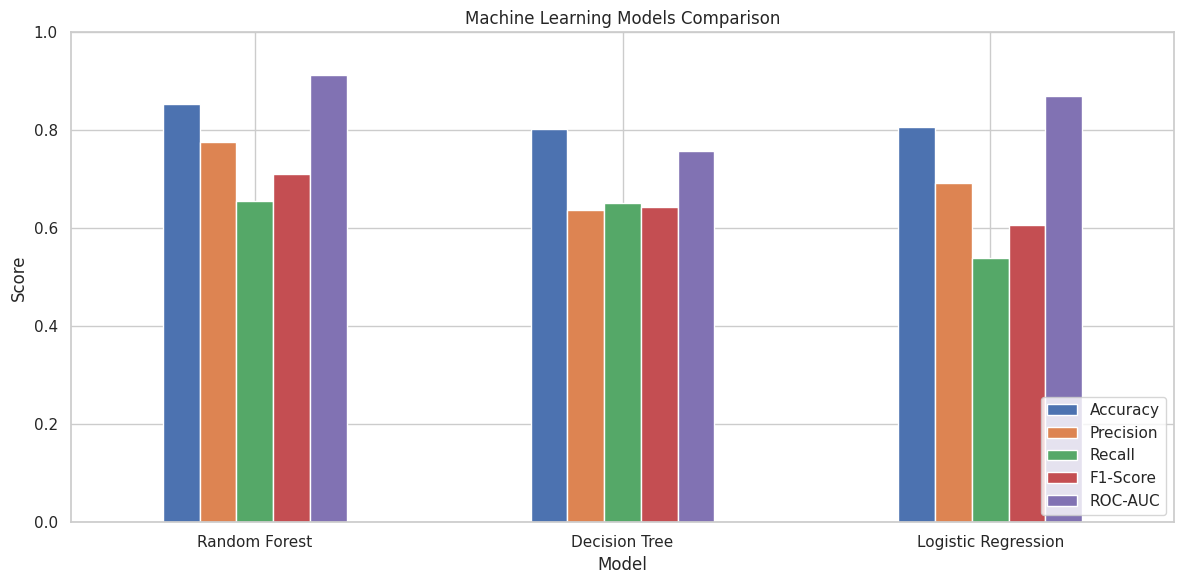

In [101]:
comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Models Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Observation:**

Random Forest achieved the best overall performance among the three evaluated models, with the highest accuracy (85.34%), precision (78%), recall (66%), F1-score (0.71), and ROC-AUC (0.9130).

Decision Tree achieved a slightly higher recall than Logistic Regression, while Logistic Regression showed better ROC-AUC.

Based on these results, Random Forest was selected for further hyperparameter tuning to improve its predictive performance.


###HYPER PARAMETER TUNING

In [102]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Define Hyperparameter Search Space

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Create Random Forest
rf_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Cross Validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_grid,
    n_iter=8,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit on Training Data
random_search.fit(X_train_processed, y_train)

# Best Parameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation F1-Score:")
print(random_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}

Best Cross Validation F1-Score:
0.6639049063154753


In [104]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Select Best Model
best_rf_model = random_search.best_estimator_

# Make Predictions
final_predictions = best_rf_model.predict(
    X_test_processed
)

# Predict Probabilities
final_probabilities = best_rf_model.predict_proba(
    X_test_processed
)[:, 1]

# Evaluate Final Model

print("Final Random Forest Accuracy:",
      accuracy_score(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    final_predictions
))

print("\nROC-AUC Score:",
      roc_auc_score(
          y_test,
          final_probabilities
      ))

Final Random Forest Accuracy: 0.8478734380373725

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90     12644
           1       0.79      0.61      0.69      4802

    accuracy                           0.85     17446
   macro avg       0.83      0.77      0.79     17446
weighted avg       0.84      0.85      0.84     17446


Confusion Matrix:
[[11880   764]
 [ 1890  2912]]

ROC-AUC Score: 0.9132847654166032


**Observation:**

Hyperparameter tuning resulted in a slight improvement
in precision and ROC-AUC, but reduced accuracy,
recall, and F1-score.

The original Random Forest model achieved better
overall classification performance, with an F1-score
of 0.711 compared to 0.69 for the tuned model.

Therefore, the original Random Forest model was
selected as the preferred model based on its
overall performance and ability to identify
canceled bookings.

<Figure size 700x500 with 0 Axes>

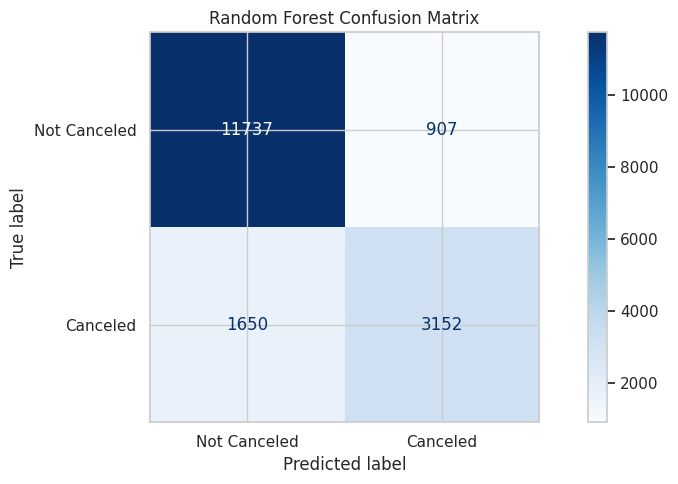

In [105]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 5))

ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test_processed,
    y_test,
    cmap="Blues",
    display_labels=["Not Canceled", "Canceled"]
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

**Observation:**

The Confusion Matrix shows that the Random Forest
model correctly classified 11,737 non-canceled
bookings and 3,152 canceled bookings.

However, the model produced 907 false positives
and 1,650 false negatives.

The model demonstrates good classification
performance, although some canceled bookings
remain undetected.

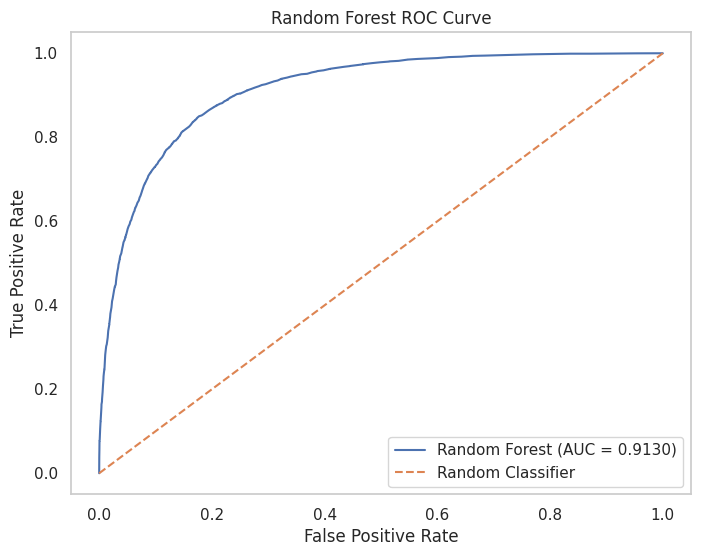

In [106]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC Curve
y_prob = rf_model.predict_proba(X_test_processed)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")

plt.legend()
plt.grid()
plt.show()

**Observation:**

The ROC Curve demonstrates the strong classification
performance of the Random Forest model.

The model achieved a ROC-AUC score of 0.9130,
indicating a high ability to distinguish between
canceled and non-canceled bookings.

The ROC curve is significantly above the random
classifier baseline, showing that the model performs
much better than random guessing.

In [107]:
# Get Feature Names After Preprocessing

feature_names = (
    preprocessing_pipeline
    .get_feature_names_out()
)

# Get Feature Importance

importances = rf_model.feature_importances_

# Create Feature Importance DataFrame

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort Features by Importance

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display Top 15 Features

display(feature_importance_df.head(15))

,Feature,Importance
0,num__lead_time,0.119034
14,num__adr,0.079205
3,num__arrival_date_day_of_month,0.063399
16,num__total_of_special_requests,0.058001
2,num__arrival_date_week_number,0.055633
104,cat__country_PRT,0.048097
5,num__stays_in_week_nights,0.045791
4,num__stays_in_weekend_nights,0.030181
15,num__required_car_parking_spaces,0.026104
1,num__arrival_date_year,0.025343


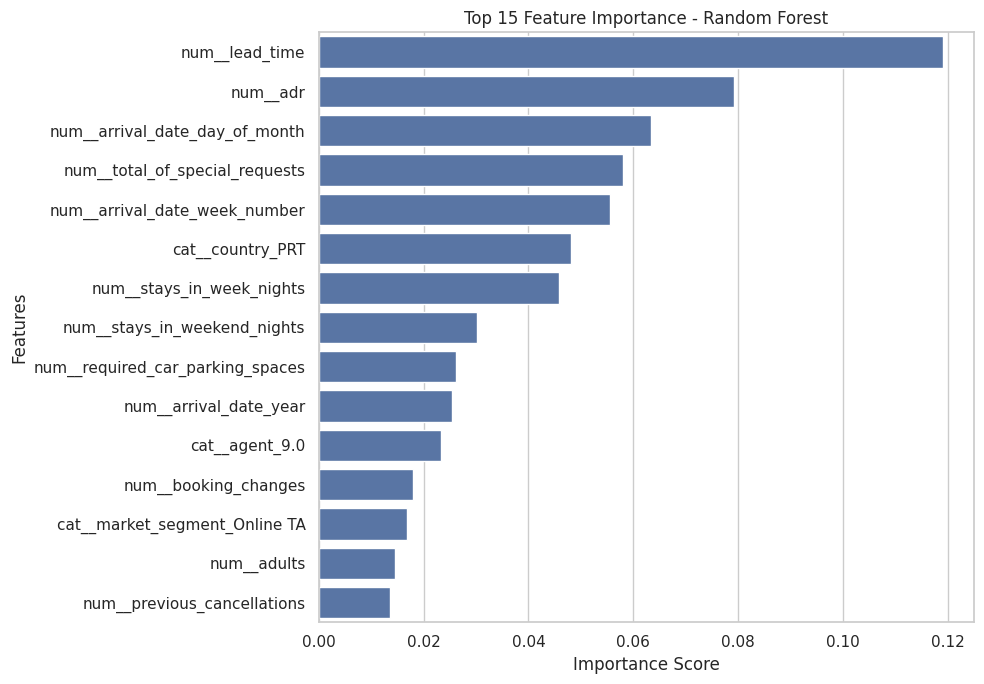

In [108]:
# Plot Top 15 Features

top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

**Observation:**

Feature Importance analysis identified Lead Time as
the most influential feature in the Random Forest model,
followed by ADR and Arrival Date Day of Month.

Total Special Requests, Arrival Week Number, and Country
also contributed significantly to the model's predictions.

These findings suggest that booking timing, pricing,
guest preferences, and booking characteristics are
important predictive factors.

However, feature importance indicates predictive
contribution rather than causation.

In [109]:
# Updated Numerical Features

updated_numerical_features = numerical_features + [
    "total_nights",
    "total_guests",
    "is_family"
]

print("Updated Numerical Features:")
print(updated_numerical_features)

print("\nTotal Features:",
      len(updated_numerical_features))

Updated Numerical Features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests', 'is_family']

Total Features: 20


In [110]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)
# Feature Engineering
def add_booking_features(data):

    data = data.copy()

    data["total_nights"] = (
        data["stays_in_weekend_nights"] +
        data["stays_in_week_nights"]
    )

    data["total_guests"] = (
        data["adults"] +
        data["children"] +
        data["babies"]
    )

    data["is_family"] = (
        (data["children"] + data["babies"]) > 0
    ).astype(int)

    return data


# Updated Feature Lists
# Numerical Preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical Preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("to_string", FunctionTransformer(
            lambda x: x.astype(str),
            feature_names_out="one-to-one"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10
        ))
    ]
)

# Combine Transformers
full_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, updated_numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Full Pipeline
full_pipeline = Pipeline(
    steps=[
        ("feature_engineering",
         FunctionTransformer(
             add_booking_features,
             validate=False
         )),

        ("preprocessor", full_preprocessor),

        ("classifier",
         RandomForestClassifier(
             random_state=42,
             n_jobs=1
         ))
    ]
)

# Hyperparameter Search
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20, 30],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

final_search = RandomizedSearchCV(
    estimator=full_pipeline,
    param_distributions=param_grid,
    n_iter=8,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using Raw Training Data
final_search.fit(X_train, y_train)

print("Best Parameters:")
print(final_search.best_params_)

print("\nBest CV F1-Score:")
print(final_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': None}

Best CV F1-Score:
0.6670391531287853


In [111]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Get Best Model
best_model = final_search.best_estimator_

# Predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Final Model Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC Score:",
      roc_auc_score(y_test, y_prob))

Final Model Accuracy: 0.8464977645305514

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90     12644
           1       0.80      0.59      0.68      4802

    accuracy                           0.85     17446
   macro avg       0.83      0.77      0.79     17446
weighted avg       0.84      0.85      0.84     17446


Confusion Matrix:
[[11937   707]
 [ 1971  2831]]

ROC-AUC Score: 0.9120378471165854


**Observation:**

The optimized Random Forest Pipeline achieved an accuracy of 84.65% and a ROC-AUC score of 0.9120.

For canceled bookings, the model achieved 80% precision, 59% recall, and an F1-score of 0.68.

The model successfully identified 2,831 canceled bookings, while 1,971 canceled bookings were incorrectly classified as non-canceled.

These results demonstrate good predictive performance, although further improvements in cancellation detection may be beneficial.

In [112]:

# Get the Final Optimized Pipeline
final_model = final_search.best_estimator_

# Get Feature Names After Final Preprocessing
feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Feature Importance from Final Random Forest
importances = (
    final_model
    .named_steps["classifier"]
    .feature_importances_
)

# Create Feature Importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort Features by Importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display Top 15 Features
display(feature_importance_df.head(15))


,Feature,Importance
0,num__lead_time,0.106009
16,num__total_of_special_requests,0.075848
107,cat__country_PRT,0.075571
14,num__adr,0.049944
15,num__required_car_parking_spaces,0.042465
135,cat__market_segment_Online TA,0.038181
322,cat__agent_9.0,0.035686
2,num__arrival_date_week_number,0.031109
17,num__total_nights,0.027933
3,num__arrival_date_day_of_month,0.027061


## Business Insights

The optimized Random Forest model achieved an accuracy of 84.65% and a ROC-AUC score of 0.9120, demonstrating strong overall classification performance.

Key findings:

1. **Cancellation Prediction:** The model achieved 80% precision for canceled bookings, meaning most bookings predicted as canceled were correctly identified.

2. **Cancellation Detection:** The model achieved 59% recall, successfully identifying 2,831 out of 4,802 actual canceled bookings.

3. **Missed Cancellations:** The model failed to identify 1,971 canceled bookings, classifying them as non-canceled.

4. **False Predictions:** 707 non-canceled bookings were incorrectly predicted as canceled.

5. **Important Factors:** Lead time, total special requests, country, ADR, and required car parking spaces were among the most influential features.

### Business Interpretation

These findings suggest that hotels can use the model to identify potentially risky bookings and improve their cancellation management strategies. However, the current recall indicates that further optimization is needed to detect a larger proportion of actual cancellations.

## Business Recommendations

Based on the model results, the following actions are recommended:

1. **Risk-Based Booking Management:** Use predicted cancellation probabilities to classify bookings into low, medium, and high-risk categories.

2. **Deposit Policies:** Consider applying stricter deposit or prepayment policies to high-risk bookings, subject to hotel policies and customer conditions.

3. **Early Monitoring:** Monitor bookings with long lead times because lead time was the most important predictive feature.

4. **Reservation Follow-up:** Send confirmation messages and reminders to customers with higher predicted cancellation risks.

5. **Model Improvement:** Improve cancellation recall to reduce the number of missed cancellations before using the model in real hotel operations.

### Expected Business Benefits

- Better reservation management.
- Reduced unexpected cancellations.
- Improved room availability planning.
- More informed deposit decisions.
- Better revenue protection.

## Model Limitations

Despite its strong overall performance, the model has several limitations:

1. **Missed Cancellations:** The recall for canceled bookings is 59%, meaning a considerable number of cancellations remain undetected.

2. **Historical Data:** Predictions are based on historical booking patterns and may not fully represent future customer behavior.

3. **Feature Limitations:** The model can only learn from the information available in the dataset.

4. **Business Context:** Feature importance indicates predictive relationships, not necessarily causal relationships.

5. **Operational Validation:** The model requires testing with real hotel booking operations before being used for actual business decisions.

In [113]:

# Load Saved Model
with open(model_path, "rb") as f:
    loaded_model = cloudpickle.load(f)

# Test Predictions
loaded_predictions = loaded_model.predict(X_test)

# Verify
print("Model Loaded Successfully!")

print("Original Predictions Match:",
      np.array_equal(y_pred, loaded_predictions))

print("Number of Predictions:", len(loaded_predictions))


Model Loaded Successfully!
Original Predictions Match: True
Number of Predictions: 17446


In [114]:

import cloudpickle
import os

# Get Best Model
best_model = final_search.best_estimator_

# Save Path
model_path = "/content/drive/MyDrive/Hotel_Cancellation_Project/hotel_cancellation_model.pkl"

# Save Model using Cloudpickle
with open(model_path, "wb") as f:
    cloudpickle.dump(best_model, f)

print("Final Model Saved Successfully!")
print("Model Path:", model_path)
print("File Size:", round(os.path.getsize(model_path) / (1024*1024), 2), "MB")


Final Model Saved Successfully!
Model Path: /content/drive/MyDrive/Hotel_Cancellation_Project/hotel_cancellation_model.pkl
File Size: 58.06 MB


In [115]:
import shutil
import os

# Copy model from Google Drive to Colab
source = "/content/drive/MyDrive/Hotel_Cancellation_Project/hotel_cancellation_model.pkl"

destination = "/content/hotel_cancellation_model.pkl"

shutil.copy2(source, destination)

print("Model copied successfully!")
print("File exists:", os.path.exists(destination))

Model copied successfully!
File exists: True


In [116]:

import os
import sys
import importlib

project_path = "/content/drive/MyDrive/Hotel_Cancellation_Project"

os.makedirs(project_path, exist_ok=True)

functions_code = '''
import numpy as np

def add_booking_features(data):
    data = data.copy()

    data["total_nights"] = (
        data["stays_in_weekend_nights"] +
        data["stays_in_week_nights"]
    )

    data["total_guests"] = (
        data["adults"] +
        data["children"] +
        data["babies"]
    )

    data["is_family"] = (
        (data["children"] + data["babies"]) > 0
    ).astype(int)

    return data


def convert_to_string(data):
    return np.asarray(data).astype(str)
'''

functions_path = os.path.join(
    project_path,
    "model_functions.py"
)

with open(functions_path, "w") as f:
    f.write(functions_code)

# Import the functions from the external module
if project_path not in sys.path:
    sys.path.insert(0, project_path)

import model_functions
importlib.reload(model_functions)

print("Model functions module created successfully!")


Model functions module created successfully!


In [117]:

import cloudpickle
import numpy as np

# Load Saved Model
with open(model_path, "rb") as f:
    loaded_model = cloudpickle.load(f)

# Generate Predictions
loaded_predictions = loaded_model.predict(X_test)

# Compare Predictions
print("Model Loaded Successfully!")

print(
    "Original Predictions Match:",
    np.array_equal(y_pred, loaded_predictions)
)

print("Number of Predictions:", len(loaded_predictions))


Model Loaded Successfully!
Original Predictions Match: True
Number of Predictions: 17446


In [118]:
import cloudpickle

model_path = "/content/drive/MyDrive/Hotel_Cancellation_Project/hotel_cancellation_model.pkl"

with open(model_path, "rb") as f:
    saved_model = cloudpickle.load(f)

print(type(saved_model))
print(saved_model)

<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('feature_engineering',
                 FunctionTransformer(func=<function add_booking_features at 0x7f5702056d40>)),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time',
                                                   'arrival_date_year',
                                                   'arrival_date_week_number',
                                                   'arrival_date_day_of_month',
                                                   'st...
                                         

In [ ]:

import os
import sys
import importlib
import numpy as np
import cloudpickle

project_path = "/content/drive/MyDrive/Hotel_Cancellation_Project"

# Update model_functions.py
functions_code = '''
import numpy as np

def add_booking_features(data):
    data = data.copy()

    data["total_nights"] = (
        data["stays_in_weekend_nights"] +
        data["stays_in_week_nights"]
    )

    data["total_guests"] = (
        data["adults"] +
        data["children"] +
        data["babies"]
    )

    data["is_family"] = (
        (data["children"] + data["babies"]) > 0
    ).astype(int)

    return data


def convert_to_string(data, dtype=None, **kwargs):
    if dtype is None:
        dtype = str

    return np.asarray(data).astype(dtype)
'''

functions_path = os.path.join(
    project_path,
    "model_functions.py"
)

with open(functions_path, "w") as f:
    f.write(functions_code)

if project_path not in sys.path:
    sys.path.insert(0, project_path)

import model_functions
importlib.reload(model_functions)

print("Functions updated successfully!")


In [119]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

best_model = final_search.best_estimator_

# Update categorical transformer
cat_transformer = (
    best_model.named_steps["preprocessor"]
    .named_transformers_["cat"]
)

def update_transformer(transformer):

    if isinstance(transformer, FunctionTransformer):
        if getattr(transformer.func, "__name__", "") == "convert_to_string":
            transformer.func = model_functions.convert_to_string

    elif isinstance(transformer, Pipeline):
        for _, step in transformer.steps:
            update_transformer(step)

update_transformer(cat_transformer)

# Update feature engineering function
best_model.named_steps[
    "feature_engineering"
].func = model_functions.add_booking_features

# Save again
model_path = os.path.join(
    project_path,
    "hotel_cancellation_model.pkl"
)

with open(model_path, "wb") as f:
    cloudpickle.dump(best_model, f)

print("Updated Model Saved Successfully!")


Updated Model Saved Successfully!


In [120]:

# Load updated model
with open(model_path, "rb") as f:
    loaded_model = cloudpickle.load(f)

# Generate predictions
original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print("Model Loaded Successfully!")

print(
    "Predictions Match:",
    np.array_equal(
        original_predictions,
        loaded_predictions
    )
)

print("Total Predictions:", len(loaded_predictions))


Model Loaded Successfully!
Predictions Match: True
Total Predictions: 17446


In [121]:
!pip install -q streamlit

In [122]:
import sklearn
import streamlit
import cloudpickle

print("Scikit-learn:", sklearn.__version__)
print("Streamlit:", streamlit.__version__)
print("Cloudpickle:", cloudpickle.__version__)

Scikit-learn: 1.6.1
Streamlit: 1.67.0
Cloudpickle: 3.1.2


In [123]:
!pip install -q plotly

In [ ]:

%%writefile /content/drive/MyDrive/Hotel_Cancellation_Project/app.py

import streamlit as st
import pandas as pd
import numpy as np
import cloudpickle
import os
import model_functions

# ==========================================
# 1. PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Hotel Booking Intelligence",
    page_icon="🏨",
    layout="wide"
)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    BASE_DIR, "hotel_cancellation_model.pkl"
)

DATA_PATH = os.path.join(
    BASE_DIR, "hotel_bookings.csv"
)

# ==========================================
# 2. LOAD MODEL AND DATA
# ==========================================

@st.cache_resource
def load_model():
    with open(MODEL_PATH, "rb") as f:
        return cloudpickle.load(f)


@st.cache_data
def load_data():
    return pd.read_csv(DATA_PATH)


try:
    model = load_model()
    df = load_data()

except Exception as e:
    st.error(f"Loading Error: {e}")
    st.stop()


# ==========================================
# 3. SIDEBAR NAVIGATION
# ==========================================

st.sidebar.title("🏨 Hotel Intelligence")

st.sidebar.caption("Booking Analytics & Prediction")

page = st.sidebar.radio(
    "Navigation",
    [
        "Dashboard Overview",
        "Cancellation Prediction"
    ]
)

st.sidebar.divider()

st.sidebar.info(
    "Hotel Booking Intelligence System"
)


# ==========================================
# 4. DASHBOARD OVERVIEW
# ==========================================

if page == "Dashboard Overview":

    st.title("🏨 Hotel Booking Intelligence")
    st.write(
        "Monitor hotel booking performance, "
        "cancellation trends and business indicators."
    )


    st.divider()

    # ==========================================
    # DASHBOARD INTERACTIVE FILTERS
    # ==========================================

    st.subheader("Dashboard Filters")

    filter_col1, filter_col2, filter_col3 = st.columns(3)

    with filter_col1:
        selected_hotels = st.multiselect(
            "Hotel Type",
            options=sorted(df["hotel"].dropna().unique()),
            default=sorted(df["hotel"].dropna().unique())
        )

    with filter_col2:
        selected_years = st.multiselect(
            "Arrival Year",
            options=sorted(df["arrival_date_year"].dropna().unique()),
            default=sorted(df["arrival_date_year"].dropna().unique())
        )

    with filter_col3:
        selected_segments = st.multiselect(
            "Market Segment",
            options=sorted(df["market_segment"].dropna().unique()),
            default=sorted(df["market_segment"].dropna().unique())
        )

    # Apply Filters
    view = df[
        df["hotel"].isin(selected_hotels) &
        df["arrival_date_year"].isin(selected_years) &
        df["market_segment"].isin(selected_segments)
    ].copy()

    if view.empty:
        st.warning("No bookings match the selected filters.")
        st.stop()

    st.divider()

    # Dataset metrics
    total_bookings = len(view)


    cancelled = int(df["is_canceled"].sum())

    not_cancelled = total_bookings - cancelled

    cancellation_rate = (
        cancelled / total_bookings * 100
        if total_bookings else 0
    )

    active_rate = (
        not_cancelled / total_bookings * 100
        if total_bookings else 0
    )

    avg_adr = df["adr"].mean()

    # KPI CARDS
    st.subheader("Key Performance Indicators")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Total Bookings",
        f"{total_bookings:,}"
    )

    col2.metric(
        "Cancelled Bookings",
        f"{cancelled:,}"
    )

    col3.metric(
        "Cancellation Rate",
        f"{cancellation_rate:.2f}%"
    )

    col4.metric(
        "Average ADR",
        f"{avg_adr:,.2f}"
    )

    st.divider()

    # SECOND ROW
    st.subheader("Booking Overview")

    col1, col2 = st.columns(2)

    with col1:

        st.markdown("#### Booking Status Distribution")

        status_data = pd.DataFrame({
            "Booking Status": [
                "Not Cancelled",
                "Cancelled"
            ],
            "Bookings": [
                not_cancelled,
                cancelled
            ]
        }).set_index("Booking Status")

        st.bar_chart(status_data)

        st.caption(
            f"Successful bookings: {active_rate:.2f}%"
        )

    with col2:

        st.markdown("#### Bookings by Hotel Type")

        hotel_counts = (
            df["hotel"]
            .value_counts()
            .rename("Bookings")
        )

        st.bar_chart(hotel_counts)

    st.divider()

    # CANCELLATION ANALYSIS
    st.subheader("Cancellation Analysis")

    col1, col2 = st.columns(2)

    with col1:

        st.markdown("#### Cancellation by Hotel Type")

        hotel_cancellation = (
            df.groupby("hotel")["is_canceled"]
            .mean()
            .mul(100)
            .rename("Cancellation Rate (%)")
        )

        st.bar_chart(hotel_cancellation)

    with col2:

        st.markdown("#### Cancellation by Deposit Type")

        deposit_cancellation = (
            df.groupby("deposit_type")["is_canceled"]
            .mean()
            .mul(100)
            .rename("Cancellation Rate (%)")
            .sort_values(ascending=False)
        )

        st.bar_chart(deposit_cancellation)

    st.divider()

    # MONTHLY ANALYSIS
    st.subheader("Monthly Booking Trends")

    month_order = [
        "January", "February", "March",
        "April", "May", "June",
        "July", "August", "September",
        "October", "November", "December"
    ]

    monthly_data = (
        df.groupby("arrival_date_month")["is_canceled"]
        .agg(["count", "mean"])
        .reindex(month_order)
    )

    monthly_data["mean"] = monthly_data["mean"] * 100

    col1, col2 = st.columns(2)

    with col1:


      monthly_data = (
          view.groupby("arrival_date_month")["is_canceled"]
          .agg(["count", "mean"])
          .reindex(month_order)
      )

      monthly_data["mean"] = monthly_data["mean"] * 100

      col1, col2 = st.columns(2)

      with col1:
          st.markdown("#### Monthly Bookings")

          st.bar_chart(
              monthly_data["count"].dropna(),
              y_label="Total Bookings"
          )

      with col2:
          st.markdown("#### Monthly Cancellation Rate")

          st.line_chart(
              monthly_data["mean"].dropna(),
              y_label="Cancellation Rate (%)"
          )


    st.divider()

    # BUSINESS SUMMARY
    st.subheader("Business Insights")

    st.write(
        f"• The dataset contains **{total_bookings:,} bookings**."
    )

    st.write(
        f"• **{cancellation_rate:.2f}%** of bookings were cancelled."
    )

    st.write(
        f"• The average daily rate (ADR) is **{avg_adr:.2f}**."
    )

    highest_hotel = hotel_cancellation.idxmax()

    st.write(
        f"• **{highest_hotel}** has the higher cancellation rate."
    )

    st.caption(
        "Insights are calculated from the uploaded historical dataset."
    )


# ==========================================
# 5. CANCELLATION PREDICTION
# ==========================================

elif page == "Cancellation Prediction":

    st.title("🔮 Hotel Cancellation Prediction")

    st.write(
        "Enter booking information to predict "
        "the probability of cancellation."
    )

    st.divider()

    with st.form("booking_form"):

        st.subheader("Hotel & Arrival Details")

        col1, col2, col3 = st.columns(3)

        with col1:
            hotel = st.selectbox(
                "Hotel Type",
                ["City Hotel", "Resort Hotel"]
            )

            arrival_date_year = st.selectbox(
                "Arrival Year",
                [2015, 2016, 2017]
            )

        with col2:
            arrival_date_month = st.selectbox(
                "Arrival Month",
                [
                    "January", "February", "March",
                    "April", "May", "June", "July",
                    "August", "September", "October",
                    "November", "December"
                ]
            )

            arrival_date_week_number = st.number_input(
                "Arrival Week Number", 1, 53, 25
            )

        with col3:
            arrival_date_day_of_month = st.number_input(
                "Arrival Day", 1, 31, 15
            )

            country = st.text_input(
                "Country Code", "PRT"
            )

        st.divider()

        st.subheader("Guest Information")

        col1, col2, col3 = st.columns(3)

        with col1:
            adults = st.number_input(
                "Adults", 0, 55, 2
            )

        with col2:
            children = st.number_input(
                "Children", 0, 10, 0
            )

        with col3:
            babies = st.number_input(
                "Babies", 0, 10, 0
            )

        st.divider()

        st.subheader("Stay Information")

        col1, col2 = st.columns(2)

        with col1:
            stays_in_weekend_nights = st.number_input(
                "Weekend Nights", 0, 19, 1
            )

            stays_in_week_nights = st.number_input(
                "Week Nights", 0, 50, 2
            )

            lead_time = st.number_input(
                "Lead Time (Days)", 0, 737, 30
            )

            meal = st.selectbox(
                "Meal",
                ["BB", "HB", "SC", "FB", "Undefined"]
            )

        with col2:
            reserved_room_type = st.text_input(
                "Reserved Room Type", "A"
            )

            assigned_room_type = st.text_input(
                "Assigned Room Type", "A"
            )

            adr = st.number_input(
                "Average Daily Rate",
                min_value=0.0,
                value=100.0
            )

        st.divider()

        st.subheader("Booking & Customer Details")

        col1, col2 = st.columns(2)

        with col1:
            market_segment = st.selectbox(
                "Market Segment",
                [
                    "Online TA", "Offline TA/TO",
                    "Groups", "Direct", "Corporate",
                    "Complementary", "Aviation",
                    "Undefined"
                ]
            )

            distribution_channel = st.selectbox(
                "Distribution Channel",
                [
                    "TA/TO", "Direct",
                    "Corporate", "GDS", "Undefined"
                ]
            )

            deposit_type = st.selectbox(
                "Deposit Type",
                [
                    "No Deposit",
                    "Non Refund",
                    "Refundable"
                ]
            )

            customer_type = st.selectbox(
                "Customer Type",
                [
                    "Transient",
                    "Transient-Party",
                    "Contract",
                    "Group"
                ]
            )

            agent = st.text_input("Agent ID", "9.0")

        with col2:
            is_repeated_guest = st.selectbox(
                "Repeated Guest", [0, 1]
            )

            previous_cancellations = st.number_input(
                "Previous Cancellations", 0, 100, 0
            )

            previous_bookings_not_canceled = st.number_input(
                "Previous Successful Bookings", 0, 100, 0
            )

            booking_changes = st.number_input(
                "Booking Changes", 0, 30, 0
            )

            days_in_waiting_list = st.number_input(
                "Days in Waiting List", 0, 400, 0
            )

            required_car_parking_spaces = st.number_input(
                "Required Parking Spaces", 0, 8, 0
            )

            total_of_special_requests = st.number_input(
                "Special Requests", 0, 5, 0
            )

        submit = st.form_submit_button(
            "Predict Cancellation",
            use_container_width=True
        )

    # ======================================
    # 6. PREDICTION RESULTS
    # ======================================

    if submit:

        if adults + children + babies == 0:

            st.error(
                "Please enter at least one guest."
            )

        else:

            input_data = pd.DataFrame([{
                "hotel": hotel,
                "lead_time": lead_time,
                "arrival_date_year": arrival_date_year,
                "arrival_date_month": arrival_date_month,
                "arrival_date_week_number": arrival_date_week_number,
                "arrival_date_day_of_month": arrival_date_day_of_month,
                "stays_in_weekend_nights": stays_in_weekend_nights,
                "stays_in_week_nights": stays_in_week_nights,
                "adults": adults,
                "children": children,
                "babies": babies,
                "meal": meal,
                "country": country.strip().upper(),
                "market_segment": market_segment,
                "distribution_channel": distribution_channel,
                "is_repeated_guest": is_repeated_guest,
                "previous_cancellations": previous_cancellations,
                "previous_bookings_not_canceled": previous_bookings_not_canceled,
                "reserved_room_type": reserved_room_type,
                "assigned_room_type": assigned_room_type,
                "booking_changes": booking_changes,
                "deposit_type": deposit_type,
                "agent": agent.strip(),
                "customer_type": customer_type,
                "adr": adr,
                "days_in_waiting_list": days_in_waiting_list,
                "required_car_parking_spaces": required_car_parking_spaces,
                "total_of_special_requests": total_of_special_requests
            }])

            try:

                prediction = model.predict(input_data)[0]

                probability = model.predict_proba(
                    input_data
                )[0][1]

                st.divider()

                st.header("Prediction Results")

                col1, col2 = st.columns(2)

                with col1:
                    st.metric(
                        "Cancellation Probability",
                        f"{probability * 100:.2f}%"
                    )

                with col2:
                    st.metric(
                        "Predicted Status",
                        "Cancelled" if prediction == 1
                        else "Not Cancelled"
                    )

                st.progress(float(probability))

                if probability < 0.30:
                    st.success("Low Cancellation Risk")

                elif probability < 0.60:
                    st.warning("Medium Cancellation Risk")

                else:
                    st.error("High Cancellation Risk")

                st.caption(
                    "Predictions are estimates based on historical "
                    "booking data and do not guarantee actual outcomes."
                )

            except Exception as e:

                st.error(f"Prediction Error: {e}")


# ==========================================
# 7. FOOTER
# ==========================================

st.sidebar.divider()

st.sidebar.caption(
    "Hotel Booking Intelligence | Machine Learning Project"
)


In [124]:

%%writefile /content/drive/MyDrive/Hotel_Cancellation_Project/requirements.txt

streamlit==1.67.0
scikit-learn==1.6.1
cloudpickle==3.1.2
pandas
numpy


Overwriting /content/drive/MyDrive/Hotel_Cancellation_Project/requirements.txt


In [125]:
import os

project_path = "/content/drive/MyDrive/Hotel_Cancellation_Project"

for file in os.listdir(project_path):
    print(file)

hotel_bookings.csv
__pycache__
hotel_cancellation_model.pkl
model_functions.py
app_backup.py
app.py
requirements.txt
streamlit.log
cloudflared-linux-amd64.deb


In [126]:
import subprocess
import requests
import time

project_path = "/content/drive/MyDrive/Hotel_Cancellation_Project"

# Start Streamlit independently
log_file = open("/content/streamlit.log", "w")

server = subprocess.Popen(
    [
        "streamlit", "run",
        f"{project_path}/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

# Check server
for i in range(15):
    try:
        response = requests.get(
            "http://127.0.0.1:8501",
            timeout=3
        )

        print("Streamlit Status:", response.status_code)
        print("Server is running!")
        break

    except requests.exceptions.RequestException:
        time.sleep(2)

else:
    print("Server failed to start.")
    print(open("/content/streamlit.log").read())

Streamlit Status: 200
Server is running!


In [127]:

import requests

response = requests.get("http://127.0.0.1:8501")

print("Status:", response.status_code)

Status: 200


In [128]:
!./cloudflared tunnel --url http://localhost:8501

/bin/bash: line 1: ./cloudflared: No such file or directory


In [129]:
import shutil

project_path = "/content/drive/MyDrive/Hotel_Cancellation_Project"

shutil.copy(
    f"{project_path}/app.py",
    f"{project_path}/app_backup.py"
)

print("Backup created successfully!")

Backup created successfully!


In [130]:

import cloudpickle
import os

# Save Model to Google Drive
model_path = "/content/drive/MyDrive/Hotel_Cancellation_Project/hotel_cancellation_model.pkl"

# Create folder if it doesn't exist
os.makedirs(os.path.dirname(model_path), exist_ok=True)

# Save the complete pipeline
with open(model_path, "wb") as f:
    cloudpickle.dump(best_model, f)

print("Final Model Saved Successfully!")
print("Saved Path:", model_path)



Final Model Saved Successfully!
Saved Path: /content/drive/MyDrive/Hotel_Cancellation_Project/hotel_cancellation_model.pkl


In [131]:
import shutil


project_dir = "/content/drive/MyDrive/Hotel_Cancellation_Project"

backup = shutil.make_archive(
    "/content/drive/MyDrive/Hotel_Cancellation_Backup",
    "zip",
    root_dir=project_dir
)

print("Backup completed!")
print("Location:", backup)

Backup completed!
Location: /content/drive/MyDrive/Hotel_Cancellation_Backup.zip


In [132]:


project_dir = "/content/drive/MyDrive/Hotel_Cancellation_Project"

for file in os.listdir(project_dir):
    path = os.path.join(project_dir, file)
    print(file, " - ", os.path.getsize(path) // 1024, "KB")

hotel_bookings.csv  -  16460 KB
__pycache__  -  4 KB
hotel_cancellation_model.pkl  -  59448 KB
model_functions.py  -  0 KB
app_backup.py  -  15 KB
app.py  -  15 KB
requirements.txt  -  0 KB
streamlit.log  -  0 KB
cloudflared-linux-amd64.deb  -  19462 KB


In [133]:
from google.colab import drive
drive.mount('/content/drive')


PROJECT_DIR = "/content/drive/MyDrive/Hotel_Cancellation_Project"
os.chdir(PROJECT_DIR)

print(os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['hotel_bookings.csv', '__pycache__', 'hotel_cancellation_model.pkl', 'model_functions.py', 'app_backup.py', 'app.py', 'requirements.txt', 'streamlit.log', 'cloudflared-linux-amd64.deb']


In [134]:
%pip install -q -r requirements.txt

In [135]:
import os
import sys
import pandas as pd
import cloudpickle

PROJECT_DIR = "/content/drive/MyDrive/Hotel_Cancellation_Project"
os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# Import custom functions before loading the model
import model_functions

# Load dataset
df = pd.read_csv("hotel_bookings.csv")

# Load saved model
with open("hotel_cancellation_model.pkl", "rb") as f:
    model = cloudpickle.load(f)

print("Dataset loaded:", df.shape)
print("Model loaded successfully!")
print("Model type:", type(model))

Dataset loaded: (119390, 32)
Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [136]:
import subprocess
import sys
import os
import time

os.chdir(PROJECT_DIR)

log_file = open("streamlit.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process ID:", process.pid)
print("Streamlit running in background!")

Streamlit process ID: 42075
Streamlit running in background!


In [137]:
!cloudflared tunnel --url http://localhost:8501

2026-11-13T13:57:40Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-13T13:57:40Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-13T13:57:43Z INF +--------------------------------------------------------------------------------------------+
2026-11-13T13:57:43Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-13T13:57:43Z INF |  https://spring-carriers-saturday-brake.trycloudflare.

In [138]:

import os

project_path = "/content/drive/MyDrive/Hotel_Cancellation_Project"

readme_content = """
# Hotel Booking Cancellation Prediction

## Project Overview
This project aims to predict whether a hotel booking will be canceled
using machine learning techniques.

The goal is to help hotels understand booking cancellation patterns
and support better reservation and resource planning decisions.

## Project Structure

- app.py: Streamlit web application.
- model_functions.py: Custom feature engineering and preprocessing functions.
- hotel_cancellation_model.pkl: Trained machine learning pipeline.
- hotel_bookings.csv: Hotel booking dataset.
- Hotel_Cancellation_Prediction.ipynb: Project analysis, EDA, preprocessing,
  model training, evaluation, and business insights.
- requirements.txt: Required Python packages.

## Machine Learning Workflow

1. Data understanding and exploratory data analysis.
2. Data cleaning and preprocessing.
3. Feature engineering.
4. Baseline model development.
5. Training and comparison of machine learning models.
6. Hyperparameter tuning using cross-validation.
7. Final model evaluation on the test dataset.
8. Model saving and deployment.

## Final Model

The final model is a tuned Random Forest Classifier
integrated into a preprocessing pipeline.

The pipeline includes:
- Missing value imputation.
- Numerical feature scaling.
- Categorical feature encoding.
- Booking feature engineering.

## Model Evaluation

The final model achieved the following test results:

- Accuracy: 84.65%
- Precision (Canceled): 80%
- Recall (Canceled): 59%
- F1-score (Canceled): 0.68
- ROC-AUC: 0.9120

## Web Application

The project includes a Streamlit application for:
- Dashboard overview.
- Hotel booking cancellation prediction.

## Installation

Clone the repository:

```bash
git clone YOUR_GITHUB_REPOSITORY_URL
cd Hotel_Cancellation_Project
```

Install dependencies:

```bash
pip install -r requirements.txt
```

Run the application:

```bash
streamlit run app.py
```

## Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- Streamlit
- Cloudpickle

## Notes

The model was evaluated using a held-out test dataset.
Predictions are intended to support business decisions and
should not be interpreted as guaranteed outcomes.
"""

gitignore_content = """
__pycache__/
*.py[cod]
.ipynb_checkpoints/
.env
.venv/
venv/
streamlit.log
.DS_Store
"""

with open(os.path.join(project_path, "README.md"), "w", encoding="utf-8") as f:
    f.write(readme_content)

with open(os.path.join(project_path, ".gitignore"), "w", encoding="utf-8") as f:
    f.write(gitignore_content)

print("README.md created:", os.path.exists(os.path.join(project_path, "README.md")))
print(".gitignore created:", os.path.exists(os.path.join(project_path, ".gitignore")))


README.md created: True
.gitignore created: True
